# Advanced Data Analytics - LSTM Wind Power Forecasting
**Student:** Sebastian Briones  
**Student Number:** 2026004  
**Module:** Advanced Data Analytics  
**Dataset:** EirGrid processed via Apache Spark (eirgrid_processed.csv)  
**Research Question:** How does a LSTM model forecast wind power generation, and how does it perform in comparison with traditional machine learning algorithms? 

In [1]:
#pip install scikit-learn
#%pip install tensorflow

In [2]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import warnings
warnings.filterwarnings("ignore")

## Data Loading

In [3]:
# Load the processed EirGrid dataset exported from the Apache Spark pipeline (Big Data Storage and Processing module)
# Resample from 15-minute to hourly intervals to reduce rows for LSTM efficiency.
df = pd.read_csv("eirgrid_processed.csv", parse_dates=["timestamp"])
df = df.set_index("timestamp")

print(f"Raw shape: {df.shape}")

df_hourly = df[["Wind Generation (MW)"]].resample("h").mean().dropna()
wind = df_hourly
print(f"Hourly shape: {wind.shape}")
wind.head()

Raw shape: (446193, 11)
Hourly shape: (111571, 1)


,Wind Generation (MW)
timestamp,
2014-01-08 00:00:00,1216.00
2014-01-08 01:00:00,1080.25
2014-01-08 02:00:00,943.50
2014-01-08 03:00:00,780.00
2014-01-08 04:00:00,699.00


## Exploratory Data Analysis


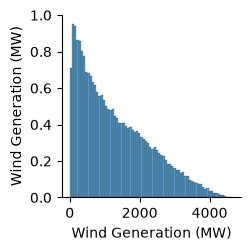

In [4]:
# Wind generation data distribution
sns.pairplot(wind)

Text(0.5, 1.0, 'Wind Generation Over Time')

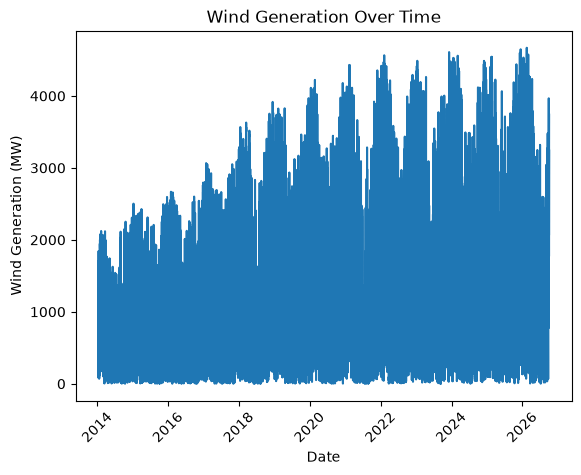

In [5]:
# Visualise wind generation over time

plt.plot(wind)
plt.ylabel ("Wind Generation (MW)")
plt.xlabel("Date")
plt.xticks(rotation = 45)
plt.title("Wind Generation Over Time")

In [6]:
# Statistics values
wind.describe()

,Wind Generation (MW)
count,111571.000000
mean,1293.433037
std,1000.431715
min,0.000000
25%,444.250000
50%,1064.000000
75%,1964.625000
max,4669.500000


In [7]:
skewness = wind["Wind Generation (MW)"].skew()
print(f"Skewness: {skewness:,.3f}")

Skewness: 0.764


## Scaler and Train/Test Split

In [8]:
# Skewness = 0.764 (right skew) MinMaxScaler selected

scaler = MinMaxScaler()

# Temporal split, same as BDSP notebook (train < 2025, test >= 2025)

train_data = wind[wind.index < pd.to_datetime("2025-01-01")]
test_data  = wind[wind.index >= pd.to_datetime("2025-01-01")]

# Fit scaler on train only — apply to both (avoids data leakage)
train_scaled = scaler.fit_transform(train_data.values)
test_scaled  = scaler.transform(test_data.values)

print(f"{'='*55}")
print(f"  TRAIN/TEST SPLIT")
print(f"{'='*55}")
print(f"  Total rows:  {len(df_hourly):,}")
print(f"  Train rows:  {len(train_scaled):,}")
print(f"  Test rows:   {len(test_scaled):,}")
print(f"{'='*55}")

  TRAIN/TEST SPLIT
  Total rows:  111,571
  Train rows:  96,217
  Test rows:   15,354


## Sliding Window (Sequence Creation)

In [9]:
# Create sequences using sliding window
# WINDOW=24 use last 24 hours to predict next hour
# Justified by Shahid et al. 2021: window captures daily wind cycles
# Pattern based on: RNN FB Stock Price.ipynb

WINDOW = 24

# Build training sequences
x_train = []
y_train = []

for i in range(WINDOW, len(train_scaled)):
    x_train.append(train_scaled[i - WINDOW:i, 0])
    y_train.append(train_scaled[i, 0])

x_train = np.array(x_train)
y_train = np.array(y_train)

# Build test sequences
x_test = []
y_test = []

for i in range(WINDOW, len(test_scaled)):
    x_test.append(test_scaled[i - WINDOW:i, 0])
    y_test.append(test_scaled[i, 0])

x_test = np.array(x_test)
y_test = np.array(y_test)

# Reshape for LSTM: (samples, timesteps, features)
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
x_test  = np.reshape(x_test,  (x_test.shape[0],  x_test.shape[1],  1))

print(f"  x_train shape: {x_train.shape}")
print(f"  y_train shape: {y_train.shape}")
print(f"  x_test shape:  {x_test.shape}")
print(f"  y_test shape:  {y_test.shape}")

  x_train shape: (96193, 24, 1)
  y_train shape: (96193,)
  x_test shape:  (15330, 24, 1)
  y_test shape:  (15330,)


## LSTM Model

In [10]:
rnn = Sequential()
rnn.add(LSTM(units = 45, return_sequences=True, input_shape = (WINDOW, 1)))
rnn.add(Dropout(0.2))

rnn.add(LSTM(units = 45, return_sequences = True))
rnn.add(Dropout(0.2))

rnn.add(LSTM(units = 45))
rnn.add(Dropout(0.2))

rnn.add(Dense(units=1))

rnn.compile(optimizer='adam', loss='mean_squared_error')

rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 45)         │         8,460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 45)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 24, 45)         │        16,380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 45)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 45)             │        16,380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 45)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            46 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,266 (161.20 KB)

 Trainable params: 41,266 (161.20 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
rnn.fit(x_train, y_train, epochs = 25, batch_size = 32)

Epoch 1/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 23s 7ms/step - loss: 0.0034
Epoch 2/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 0.0011
Epoch 3/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 0.0010
Epoch 4/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 9.5930e-04
Epoch 5/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - loss: 9.3274e-04
Epoch 6/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 9.1202e-04
Epoch 7/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 9.0138e-04
Epoch 8/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 8.7363e-04
Epoch 9/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 8.7949e-04
Epoch 10/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 8.6283e-04
Epoch 11/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 8.5934e-04
Epoch 12/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 8.5907e-04
Epoch 13/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - loss: 8.5318e-04
Epoch 14/25
3007/3007 ━━━━━━━━━━━━━━━━━━━━ 21s

In [12]:
# Generate predictions and inverse transform to original MW scale
y_pred_scaled = rnn.predict(x_test)

y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = 1 - (np.sum((y_true - y_pred)**2) / np.sum((y_true - np.mean(y_true))**2))

print(f"{'='*50}")
print(f"  LSTM - RESULTS")
print(f"{'='*50}")
print(f"  RMSE: {rmse:,.2f} MW")
print(f"  MAE:  {mae:,.2f} MW")
print(f"  R²:   {r2:.4f}")
print(f"{'='*50}")
print(f"  Baseline (Linear Reg): RMSE=323.38 MW | R²=0.9099")
print(f"  Improvement: {((323.38 - rmse) / 323.38 * 100):+.1f}% RMSE")
print(f"{'='*50}")

480/480 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
  LSTM - RESULTS
  RMSE: 139.57 MW
  MAE:  101.62 MW
  R²:   0.9832
  Baseline (Linear Reg): RMSE=323.38 MW | R²=0.9099
  Improvement: +56.8% RMSE


In [7]:
# Two LSTM layers with Dropout to prevent overfitting
# Source: Chollet (2021) — Deep Learning with Python, Chapter 10

rnn = Sequential([
    LSTM(45, return_sequences=True, input_shape=(WINDOW, 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

rnn.compile(optimizer='adam', loss='mean_squared_error')
rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

## Training

Epoch 1/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 0.0025 - val_loss: 8.5600e-04
Epoch 2/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - loss: 9.0676e-04 - val_loss: 8.6728e-04
Epoch 3/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - loss: 8.4655e-04 - val_loss: 8.3954e-04
Epoch 4/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - loss: 8.1361e-04 - val_loss: 7.2936e-04
Epoch 5/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - loss: 7.9839e-04 - val_loss: 7.0191e-04
Epoch 6/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - loss: 7.8956e-04 - val_loss: 7.3500e-04
Epoch 7/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - loss: 7.7139e-04 - val_loss: 7.3738e-04
Epoch 8/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 7.6987e-04 - val_loss: 7.6692e-04
Epoch 9/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - loss: 7.6707e-04 - val_loss: 7.3088e-04
Epoch 10/10
2706/2706 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - loss: 7.5871e-04 - val_loss: 7.1379e-04


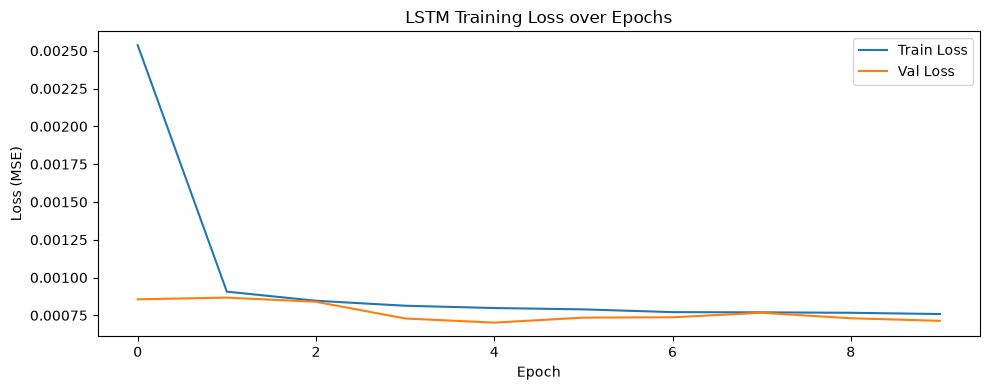

In [8]:
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# Training loss curve
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('LSTM Training Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.tight_layout()
plt.show()

## Predictions & Metrics

In [9]:
# Generate predictions and inverse transform to original MW scale
y_pred_scaled = model.predict(X_test)

y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = 1 - (np.sum((y_true - y_pred)**2) / np.sum((y_true - np.mean(y_true))**2))

print(f"{'='*50}")
print(f"  LSTM - RESULTS")
print(f"{'='*50}")
print(f"  RMSE: {rmse:,.2f} MW")
print(f"  MAE:  {mae:,.2f} MW")
print(f"  R²:   {r2:.4f}")
print(f"{'='*50}")
print(f"  Baseline (Linear Reg): RMSE=323.38 MW | R²=0.9099")
print(f"  Improvement: {((323.38 - rmse) / 323.38 * 100):+.1f}% RMSE")
print(f"{'='*50}")

480/480 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
  LSTM — RESULTS
  RMSE: 122.18 MW
  MAE:  89.73 MW
  R²:   0.9871
  Baseline (Linear Reg): RMSE=323.38 MW | R²=0.9099
  Improvement: +62.2% RMSE


## Visualisation

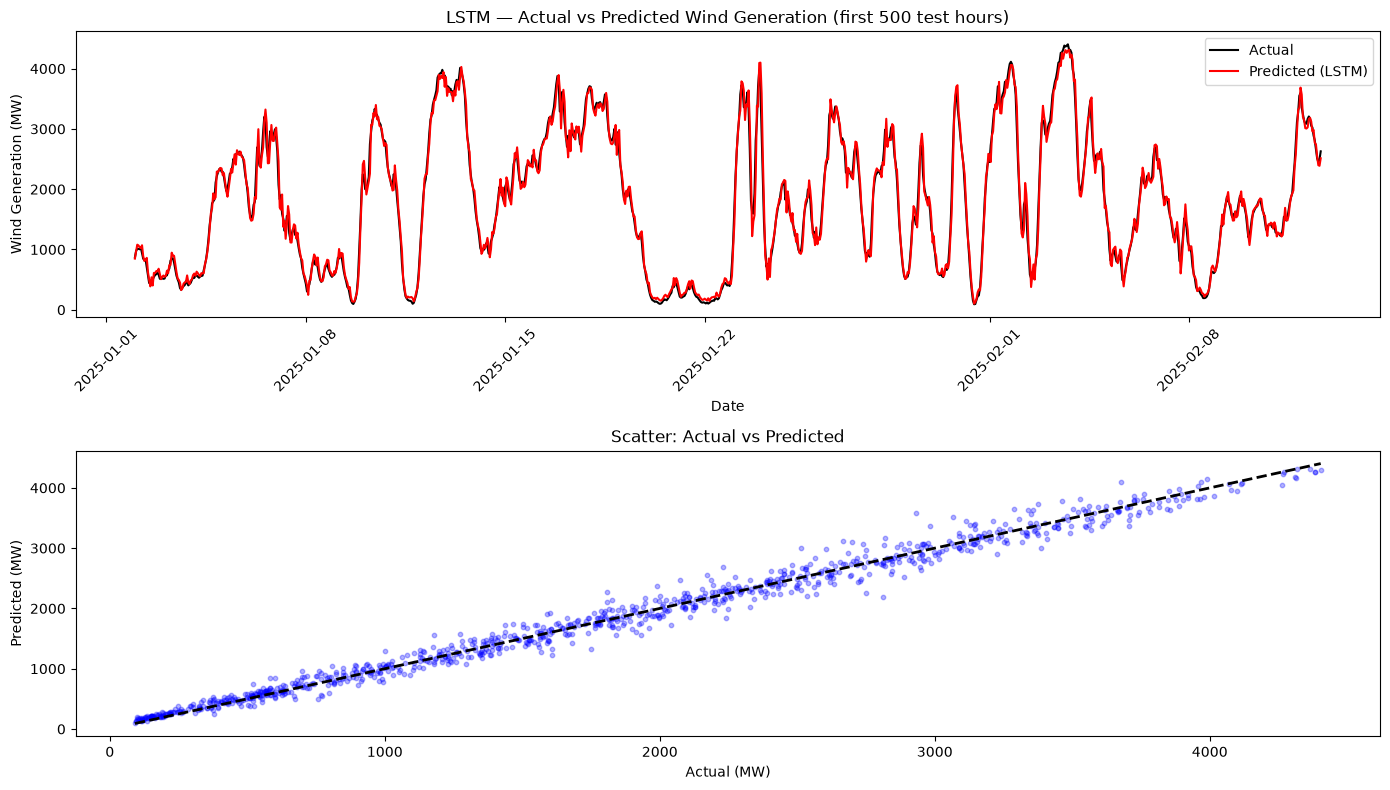

In [18]:
# Plots Actual vs Predicted                                                                                
test_dates = test_data.index[24:1024]                                                                                                                     
                                                                                                                                                           
actual_plot    = y_true[:1000].flatten()                                                                                                                  
predicted_plot = y_pred[:1000].flatten()                                                                                                                  
                                                                                                                                                           
fig, axes = plt.subplots(2, 1, figsize=(14, 8))                                                                                                          
                                                                                                                                                           
axes[0].plot(test_dates, actual_plot,    color="black", label="Actual")                                                               
axes[0].plot(test_dates, predicted_plot, color="red", label="Predicted (LSTM)")                                                   
axes[0].set_title("LSTM — Actual vs Predicted Wind Generation (first 500 test hours)")                                                                   
axes[0].set_xlabel("Date")                                                                                                                               
axes[0].set_ylabel("Wind Generation (MW)")                                                                                                               
axes[0].tick_params(axis='x', rotation=45)                                                                                                               
axes[0].legend()

# Scatter Plot

axes[1].scatter(actual_plot, predicted_plot, alpha=0.3, color="blue", s=10)                                                                         
axes[1].plot([actual_plot.min(), actual_plot.max()],                                                                                                     
               [actual_plot.min(), actual_plot.max()], 'k--', lw=2)                                                                                        
axes[1].set_title("Scatter: Actual vs Predicted")                                                                                                        
axes[1].set_xlabel("Actual (MW)")                                                                                                                        
axes[1].set_ylabel("Predicted (MW)")                                                                                                                     
                                                                                                                                                           
plt.tight_layout()                                                                                                                                       
plt.show()    